# Customer Churn: Exploratory Data Analysis

Dataset: **IBM Telco Customer Churn**: 7,043 customers, 20 attributes (demographics, services, account and billing) and whether they left in the last month.

In [1]:
import sys; sys.path.insert(0, '..')
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from src.data import download, clean
from src.features import add_features
sns.set_theme(style='whitegrid', palette='Set2')
pd.set_option('display.max_columns', 30)

## 1. Raw data & quality checks

In [2]:
raw = pd.read_csv(download())
print(raw.shape)
raw.head()

(7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [3]:
print('dtypes of numeric-looking columns:'); print(raw[['tenure', 'MonthlyCharges', 'TotalCharges']].dtypes)
blank = raw['TotalCharges'].astype(str).str.strip() == ''
print('\nBlank TotalCharges:', blank.sum(), '| their tenure values:', raw.loc[blank, 'tenure'].unique())
print('Duplicate customer IDs:', raw['customerID'].duplicated().sum())
print('Missing values:', raw.isna().sum().sum())

dtypes of numeric-looking columns:
tenure              int64
MonthlyCharges    float64
TotalCharges          str
dtype: object

Blank TotalCharges: 11 | their tenure values: [0]
Duplicate customer IDs: 0
Missing values: 0


`TotalCharges` is stored as text, and its 11 blanks all belong to customers with **tenure 0**, who haven't been billed yet. So they are filled with 0 rather than the mean, which would be wrong.

In [4]:
df = add_features(clean(raw))
print(df.shape)
df.describe().T

(7043, 26)


,count,mean,std,min,25%,50%,75%,max
tenure,7043.0,32.371149,24.559481,0.000,9.000000,29.0000,55.000000,72.000
MonthlyCharges,7043.0,64.761692,30.090047,18.250,35.500000,70.3500,89.850000,118.750
TotalCharges,7043.0,2279.734304,2266.794470,0.000,398.550000,1394.5500,3786.600000,8684.800
Churn,7043.0,0.265370,0.441561,0.000,0.000000,0.0000,1.000000,1.000
num_services,7043.0,4.146244,2.312720,1.000,2.000000,4.0000,6.000000,9.000
avg_monthly_spend,7043.0,64.762906,30.189796,13.775,35.935156,70.3375,90.174158,121.400
charge_increase,7043.0,-0.001213,2.614121,-18.900,-1.159091,0.0000,1.145567,19.125
has_family,7043.0,0.534289,0.498858,0.000,0.000000,1.0000,1.000000,1.000
auto_payment,7043.0,0.435326,0.495835,0.000,0.000000,0.0000,1.000000,1.000


## 2. Target: class imbalance

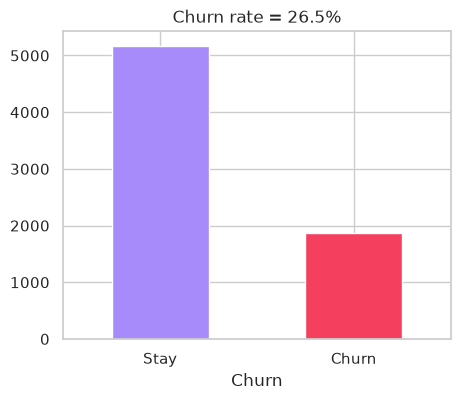

In [5]:
rate = df['Churn'].mean()
ax = df['Churn'].map({0: 'Stay', 1: 'Churn'}).value_counts().plot.bar(rot=0, color=['#a78bfa', '#f43f5e'], figsize=(5, 4))
ax.set_title(f'Churn rate = {rate:.1%}'); plt.show()

~26.5% churn: imbalanced, so accuracy is misleading (predicting 'stay' for everyone gives ~73.5%). We use **PR-AUC**, recall and a business cost instead.

## 3. Churn rate by key categories

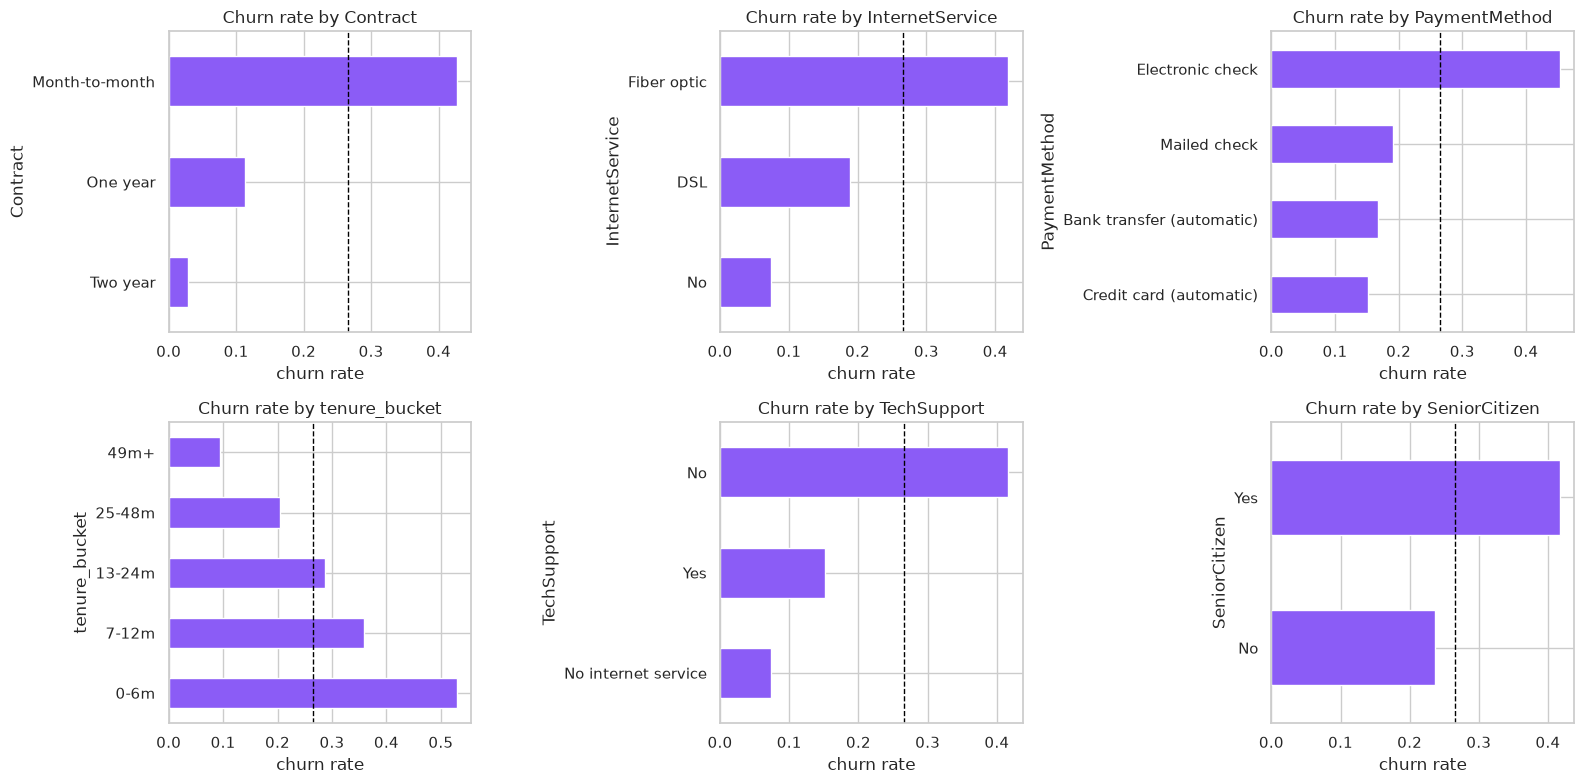

In [6]:
cols = ['Contract', 'InternetService', 'PaymentMethod', 'tenure_bucket', 'TechSupport', 'SeniorCitizen']
fig, axes = plt.subplots(2, 3, figsize=(16, 8))
for ax, c in zip(axes.flat, cols):
    order = ['0-6m', '7-12m', '13-24m', '25-48m', '49m+'] if c == 'tenure_bucket' else None
    s = df.groupby(c)['Churn'].mean().reindex(order) if order else df.groupby(c)['Churn'].mean().sort_values()
    s.plot.barh(ax=ax, color='#8b5cf6'); ax.axvline(rate, color='k', ls='--', lw=1); ax.set_title(f'Churn rate by {c}'); ax.set_xlabel('churn rate')
plt.tight_layout(); plt.show()

## 4. Numeric features vs churn

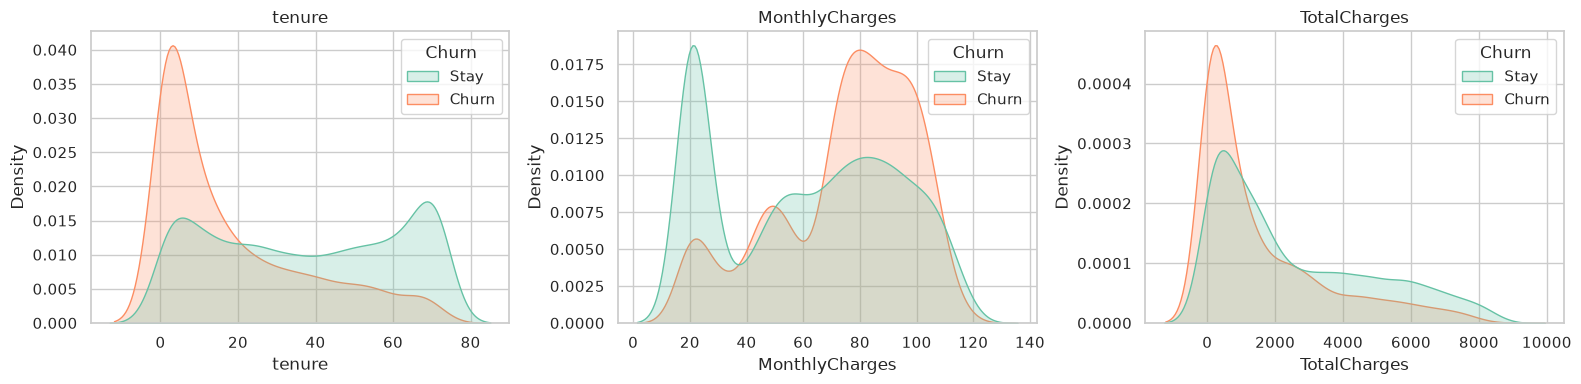

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, c in zip(axes, ['tenure', 'MonthlyCharges', 'TotalCharges']):
    sns.kdeplot(data=df, x=c, hue=df['Churn'].map({0: 'Stay', 1: 'Churn'}), fill=True, common_norm=False, ax=ax)
    ax.set_title(c)
plt.tight_layout(); plt.show()

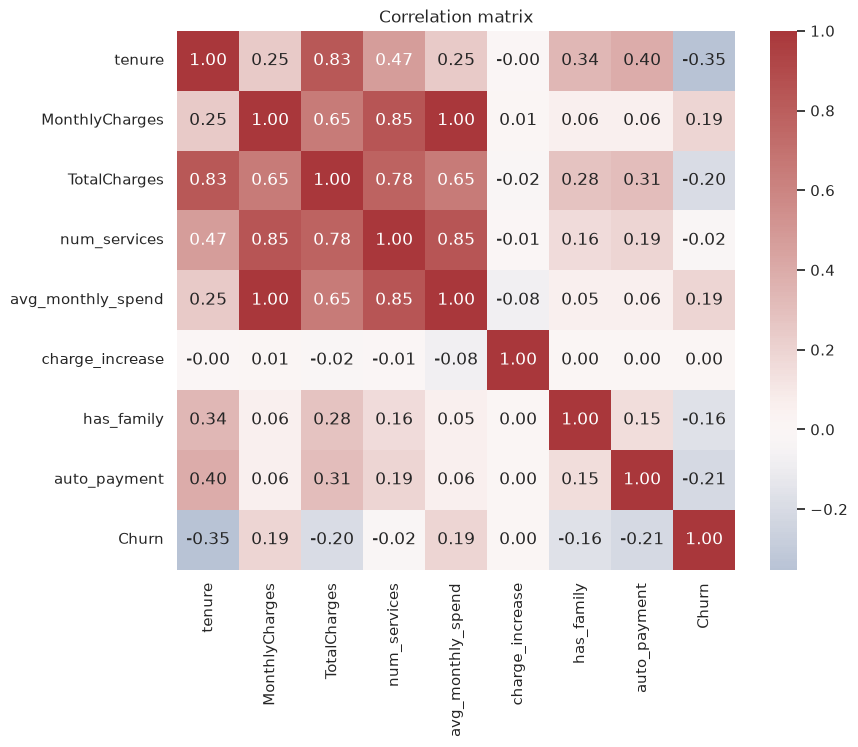

In [8]:
num = ['tenure', 'MonthlyCharges', 'TotalCharges', 'num_services', 'avg_monthly_spend', 'charge_increase', 'has_family', 'auto_payment', 'Churn']
plt.figure(figsize=(9, 7)); sns.heatmap(df[num].corr(), annot=True, fmt='.2f', cmap='vlag', center=0); plt.title('Correlation matrix'); plt.show()

`TotalCharges` is strongly correlated with `tenure` (it is roughly tenure × monthly charge). This multicollinearity matters for interpreting logistic regression coefficients, but not for tree models.

## 5. Key findings (computed)

In [9]:
g = lambda c: df.groupby(c)['Churn'].mean()
print(f"Month-to-month churn: {g('Contract')['Month-to-month']:.1%} vs two-year: {g('Contract')['Two year']:.1%}")
print(f"Fiber optic churn: {g('InternetService')['Fiber optic']:.1%} vs DSL: {g('InternetService')['DSL']:.1%}")
print(f"Electronic check churn: {g('PaymentMethod')['Electronic check']:.1%}")
print(f"First 6 months churn: {g('tenure_bucket')['0-6m']:.1%} vs 49m+: {g('tenure_bucket')['49m+']:.1%}")
print(f"No tech support churn: {g('TechSupport')['No']:.1%} vs with: {g('TechSupport')['Yes']:.1%}")

Month-to-month churn: 42.7% vs two-year: 2.8%
Fiber optic churn: 41.9% vs DSL: 19.0%
Electronic check churn: 45.3%
First 6 months churn: 52.9% vs 49m+: 9.5%
No tech support churn: 41.6% vs with: 15.2%


## 6. Model results
Produced by `python -m src.train`.

In [10]:
pd.read_csv('../reports/metrics.csv')

,model,cv_pr_auc,roc_auc,pr_auc,precision,recall,f1
0,logistic_regression,0.6613,0.8446,0.6512,0.5121,0.7914,0.6218
1,random_forest,0.6627,0.8428,0.6534,0.5284,0.7968,0.6354
2,xgboost,0.6659,0.8470,0.6629,0.5128,0.8021,0.6257


In [11]:
import json; json.load(open('../reports/business_metrics.json'))

{'best_model': 'xgboost',
 'threshold': 0.42,
 'offer_cost': 50,
 'churn_cost': 500,
 'offer_success': 0.5,
 'test_cost_no_action': 187000,
 'test_cost_threshold_0.5': 141250,
 'test_cost_tuned': 141500,
 'test_savings_vs_no_action': 45500,
 'tuned_roc_auc': 0.8469955307551216,
 'tuned_pr_auc': 0.6629332677710378,
 'tuned_precision': 0.47575757575757577,
 'tuned_recall': 0.839572192513369,
 'tuned_f1': 0.6073500967117988}

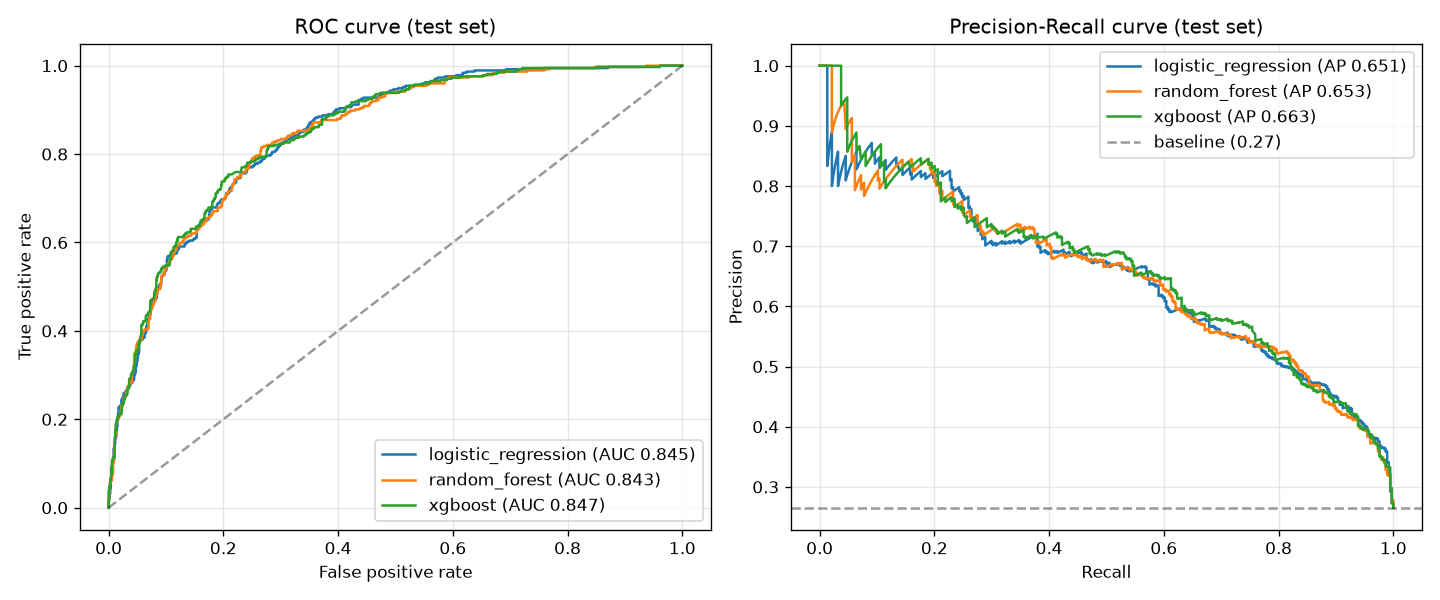

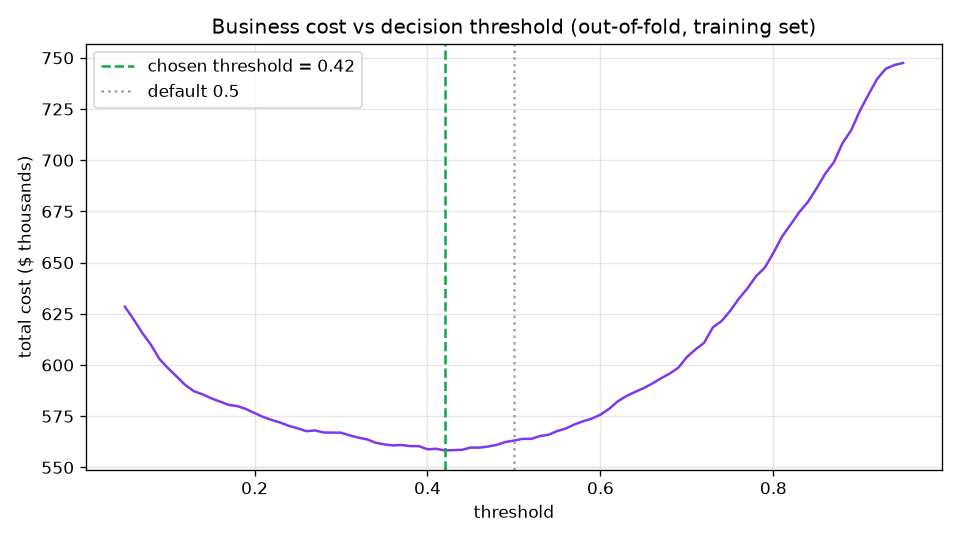

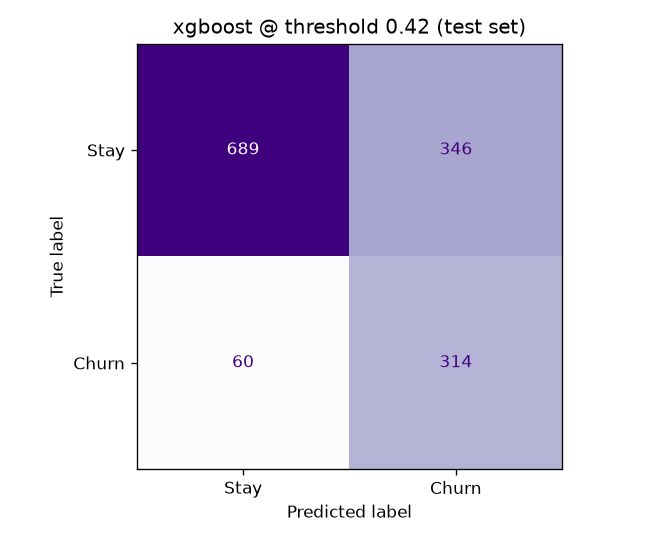

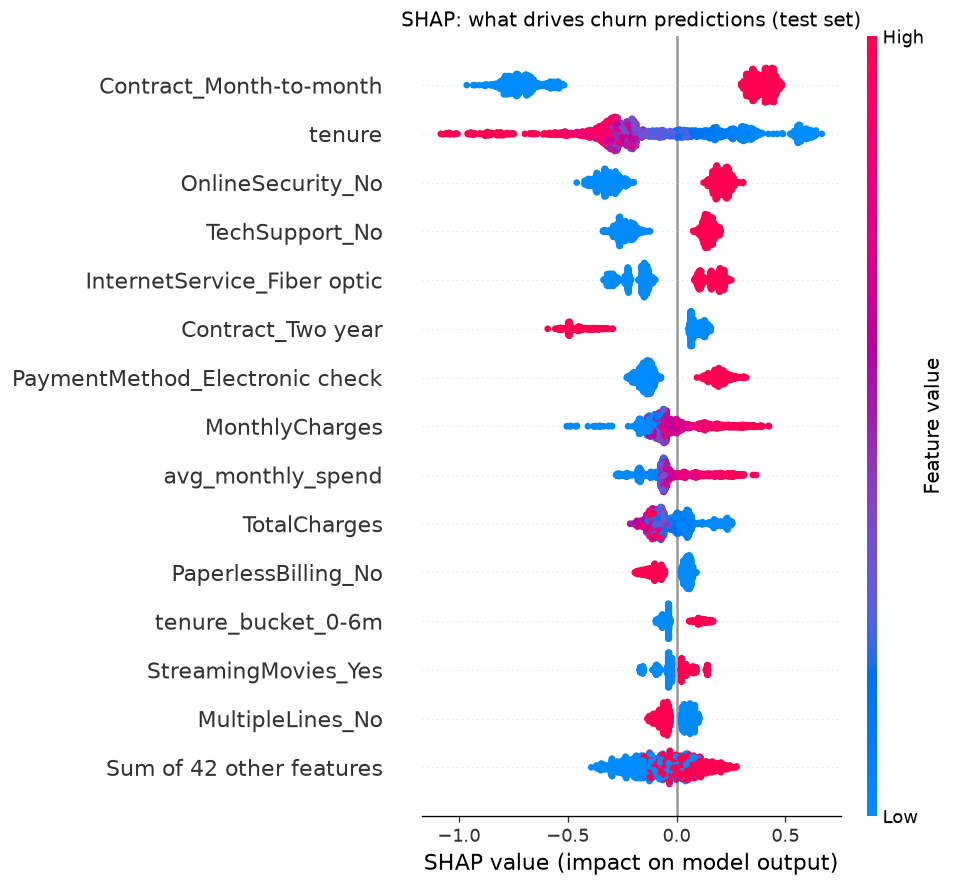

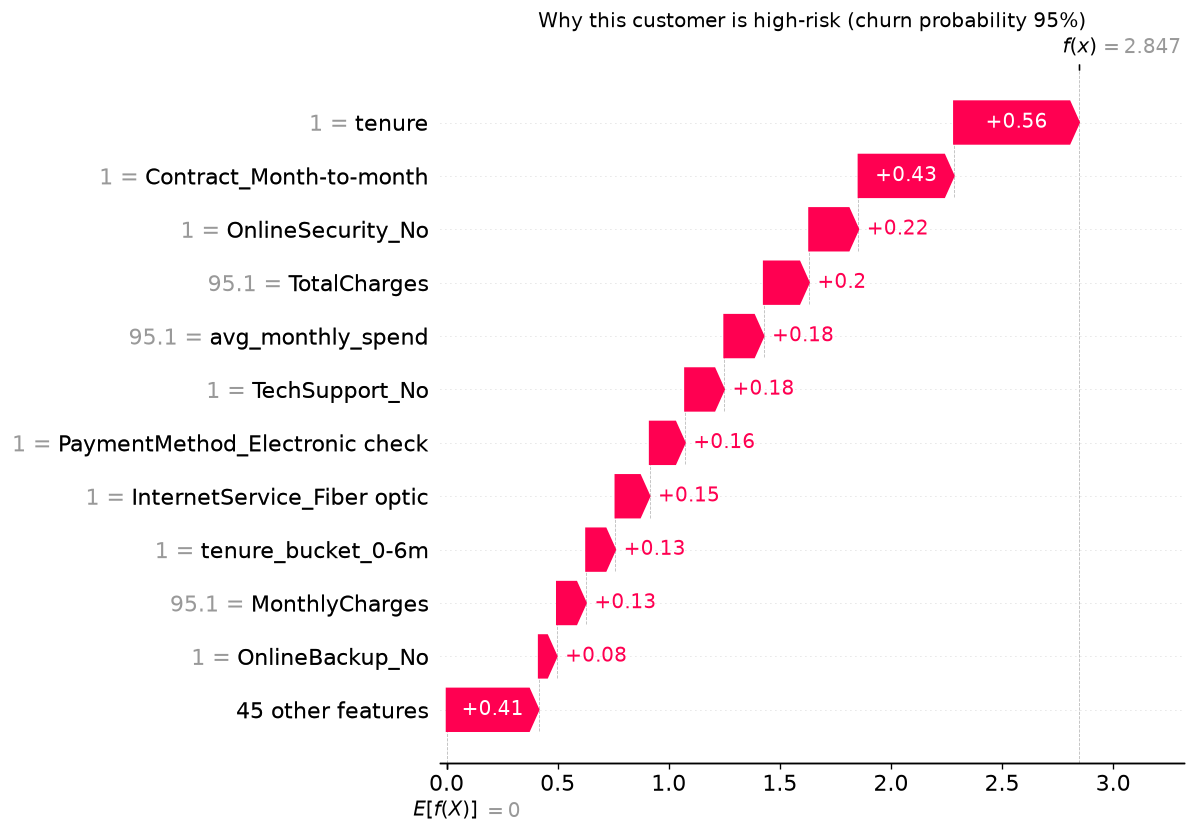

In [12]:
from IPython.display import Image, display
for f in ['roc_pr_curves.png', 'cost_vs_threshold.png', 'confusion_matrix.png', 'shap_summary.png', 'shap_customer.png']:
    display(Image(filename=f'../reports/{f}'))